In [18]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import folium

In [19]:
api_key = "72f9529ddb39f9574f15a1b0dfec4313"

city = "Pune"

url = "https://api.openweathermap.org/data/2.5/forecast"

params = {
    "q": city,
    "appid": api_key,
    "units": "metric"
}

response = requests.get(url, params=params, timeout=20)

data = response.json()


In [20]:
response

<Response [200]>

In [21]:
data

{'cod': '200',
 'message': 0,
 'cnt': 40,
 'list': [{'dt': 1793599200,
   'main': {'temp': 22.3,
    'feels_like': 22.86,
    'temp_min': 22.3,
    'temp_max': 23.35,
    'pressure': 1016,
    'sea_level': 1016,
    'grnd_level': 943,
    'humidity': 87,
    'temp_kf': -1.05,
    'dew_point': 20.03},
   'weather': [{'id': 500,
     'main': 'Rain',
     'description': 'light rain',
     'icon': '10d'}],
   'clouds': {'all': 85},
   'wind': {'speed': 2.2, 'deg': 112, 'gust': 2.96},
   'visibility': 10000,
   'pop': 0.54,
   'rain': {'3h': 0.7},
   'sys': {'pod': 'd'},
   'dt_txt': '2026-11-02 06:00:00'},
  {'dt': 1793610000,
   'main': {'temp': 23.26,
    'feels_like': 23.81,
    'temp_min': 23.26,
    'temp_max': 25.17,
    'pressure': 1015,
    'sea_level': 1015,
    'grnd_level': 940,
    'humidity': 83,
    'temp_kf': -1.91,
    'dew_point': 20.21},
   'weather': [{'id': 500,
     'main': 'Rain',
     'description': 'light rain',
     'icon': '10d'}],
   'clouds': {'all': 90},
   'wi

In [22]:
weather_data = []

for item in data["list"]:
    weather_data.append({
        "Date": item["dt_txt"],
        "Temperature": item["main"]["temp"],
        "Humidity": item["main"]["humidity"],
        "Wind": item["wind"]["speed"],
        "Weather": item["weather"][0]["description"],
        "Rain": item.get("rain", {}).get("3h", 0)
    })

df = pd.DataFrame(weather_data)

df.head()

,Date,Temperature,Humidity,Wind,Weather,Rain
0,2026-11-02 06:00:00,22.30,87,2.20,light rain,0.70
1,2026-11-02 09:00:00,23.26,83,0.91,light rain,0.58
2,2026-11-02 12:00:00,26.77,78,1.62,light rain,0.12
3,2026-11-02 15:00:00,24.32,81,0.46,light rain,1.72
4,2026-11-02 18:00:00,25.86,82,2.01,light rain,1.93


In [23]:
df.head()

df.shape

df.info()

df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Date         40 non-null     object 
 1   Temperature  40 non-null     float64
 2   Humidity     40 non-null     int64  
 3   Wind         40 non-null     float64
 4   Weather      40 non-null     object 
 5   Rain         40 non-null     float64
dtypes: float64(3), int64(1), object(2)
memory usage: 2.0+ KB


,0
Date,0
Temperature,0
Humidity,0
Wind,0
Weather,0
Rain,0


In [24]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

In [25]:
columns = ["Temperature", "Humidity", "Wind", "Rain"]

for col in columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

for col in columns:
    if df[col].notna().any():
        df[col] = df[col].fillna(df[col].median())

In [26]:
df["Weather"] = df["Weather"].fillna("Unknown")

In [27]:
df = df.dropna(subset=["Date"])

In [28]:
df.head()

,Date,Temperature,Humidity,Wind,Weather,Rain
0,2026-11-02 06:00:00,22.30,87,2.20,light rain,0.70
1,2026-11-02 09:00:00,23.26,83,0.91,light rain,0.58
2,2026-11-02 12:00:00,26.77,78,1.62,light rain,0.12
3,2026-11-02 15:00:00,24.32,81,0.46,light rain,1.72
4,2026-11-02 18:00:00,25.86,82,2.01,light rain,1.93


In [29]:
df.isnull().sum()

,0
Date,0
Temperature,0
Humidity,0
Wind,0
Weather,0
Rain,0


In [30]:
print("Average Temperature:", df["Temperature"].mean())

print("Maximum Temperature:", df["Temperature"].max())

print("Minimum Temperature:", df["Temperature"].min())

print("Average Humidity:", df["Humidity"].mean())

print("Maximum Wind Speed:", df["Wind"].max())

print("Total Rainfall:", df["Rain"].sum())

Average Temperature: 25.881999999999998
Maximum Temperature: 32.11
Minimum Temperature: 21.56
Average Humidity: 60.625
Maximum Wind Speed: 3.58
Total Rainfall: 9.85


In [31]:
df["Day"] = df["Date"].dt.date

daily = df.groupby("Day").agg({
    "Temperature": "mean",
    "Humidity": "mean",
    "Wind": "mean",
    "Rain": "sum"
})

print("Daily Weather Statistics:")
print(daily)

Daily Weather Statistics:
            Temperature   Humidity     Wind  Rain
Day                                              
2026-11-02    24.566667  82.666667  1.43500  5.21
2026-11-03    26.258750  67.375000  1.43250  4.12
2026-11-04    26.122500  61.250000  1.75125  0.52
2026-11-05    26.408750  53.625000  2.02000  0.00
2026-11-06    26.457500  46.875000  2.10000  0.00
2026-11-07    22.950000  48.000000  2.14000  0.00


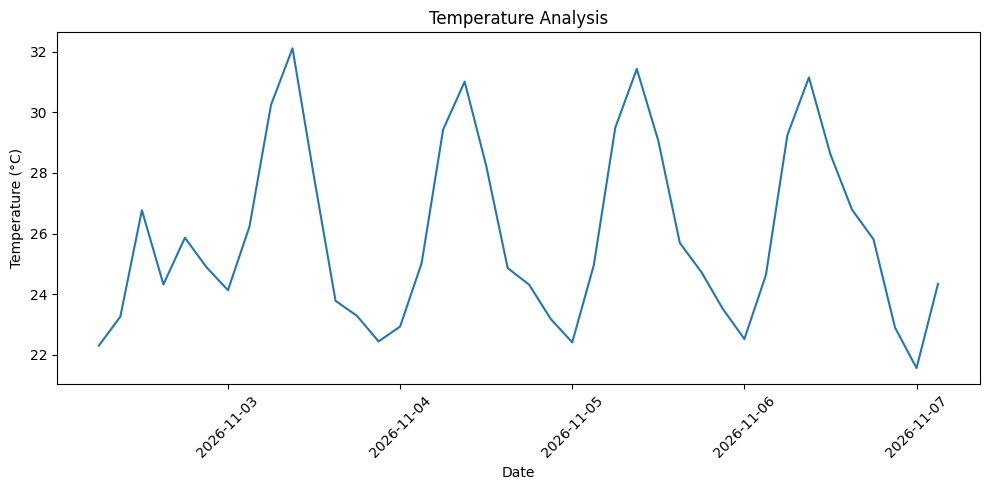

In [32]:
plt.figure(figsize=(10, 5))

plt.plot(df["Date"], df["Temperature"])

plt.title("Temperature Analysis")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

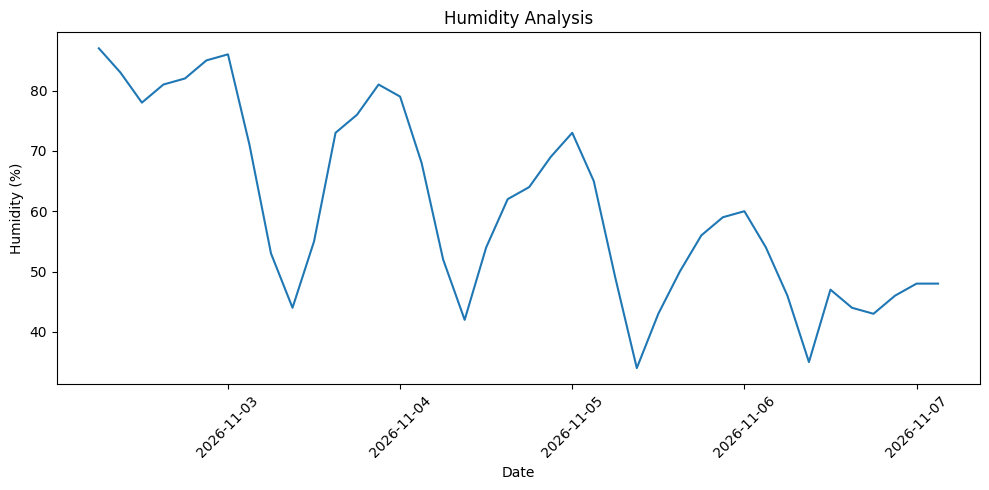

In [33]:
plt.figure(figsize=(10, 5))

plt.plot(df["Date"], df["Humidity"])

plt.title("Humidity Analysis")
plt.xlabel("Date")
plt.ylabel("Humidity (%)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

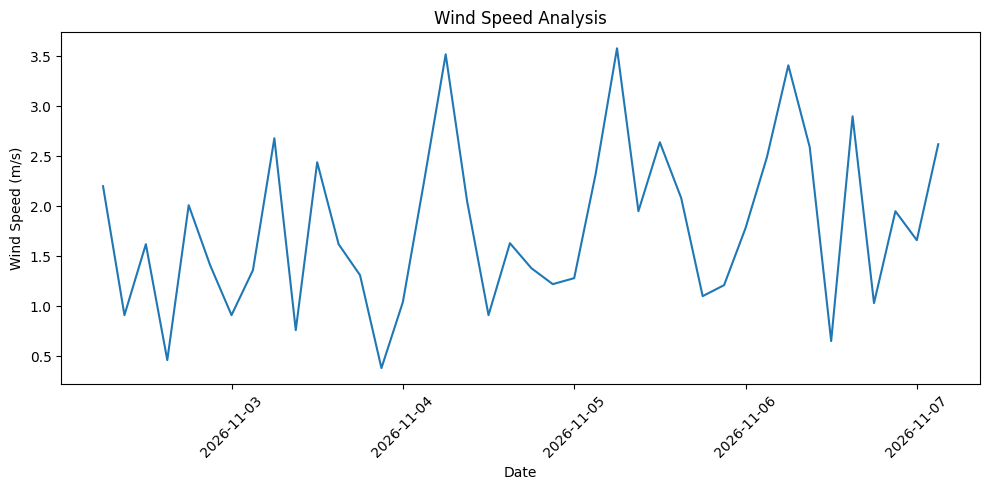

In [34]:
plt.figure(figsize=(10, 5))

plt.plot(df["Date"], df["Wind"])

plt.title("Wind Speed Analysis")
plt.xlabel("Date")
plt.ylabel("Wind Speed (m/s)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

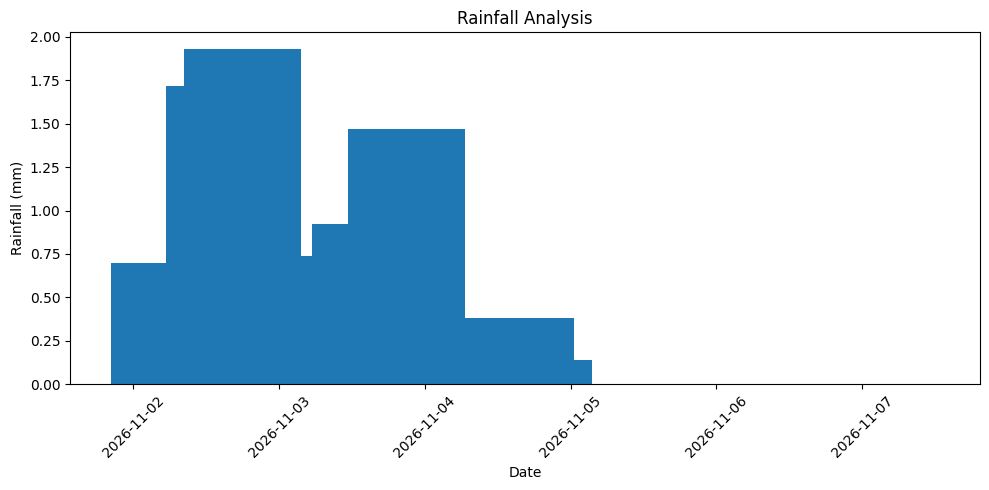

In [35]:
plt.figure(figsize=(10, 5))

plt.bar(df["Date"], df["Rain"])

plt.title("Rainfall Analysis")
plt.xlabel("Date")
plt.ylabel("Rainfall (mm)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

             Temperature  Humidity      Wind      Rain
Temperature     1.000000 -0.633111  0.403066 -0.204787
Humidity       -0.633111  1.000000 -0.447778  0.516452
Wind            0.403066 -0.447778  1.000000 -0.345988
Rain           -0.204787  0.516452 -0.345988  1.000000


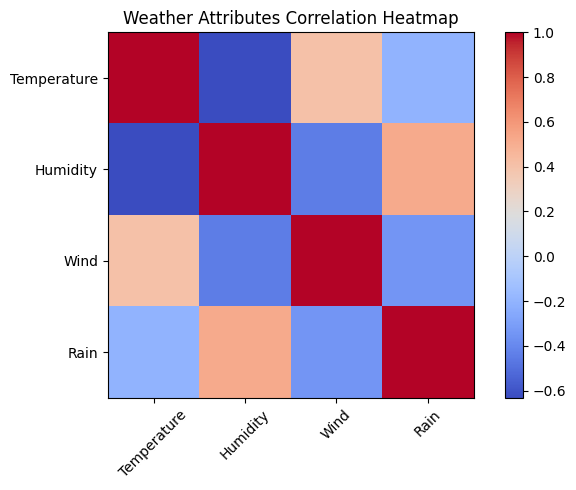

In [36]:
correlation = df[
    ["Temperature", "Humidity", "Wind", "Rain"]
].corr()

print(correlation)

plt.figure(figsize=(7, 5))

plt.imshow(correlation, cmap="coolwarm")

plt.colorbar()

plt.xticks(range(len(correlation.columns)), correlation.columns, rotation=45)
plt.yticks(range(len(correlation.columns)), correlation.columns)

plt.title("Weather Attributes Correlation Heatmap")

plt.tight_layout()
plt.show()

In [39]:
import folium

latitude = data["city"]["coord"]["lat"]
longitude = data["city"]["coord"]["lon"]

weather_map = folium.Map(
    location=[latitude, longitude],
    zoom_start=10
)

folium.Marker(
    [latitude, longitude],
    popup="Pune Weather Location"
).add_to(weather_map)

weather_map

In [40]:
weather_map.save("Pune_Weather_Map.html")

In [38]:
!pip install folium